# The Application of computational physics methods in finance -- Ali Khabazian // june 2024

1.2 Stochastic Caloculus in Finance

1.2.1 Brownian motion

In [1]:
import math
import itertools
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

Symmetric random walk

In [2]:
#parameters
M = 10   #number of simulations
t = 10   #time

In [17]:
random_walk = [-1, 1]
steps = np.random.choice(random_walk, size = (M,t)).T
origin = np.zeros((1,M))
rw_paths = np.concatenate([origin, steps]).cumsum(axis=0)

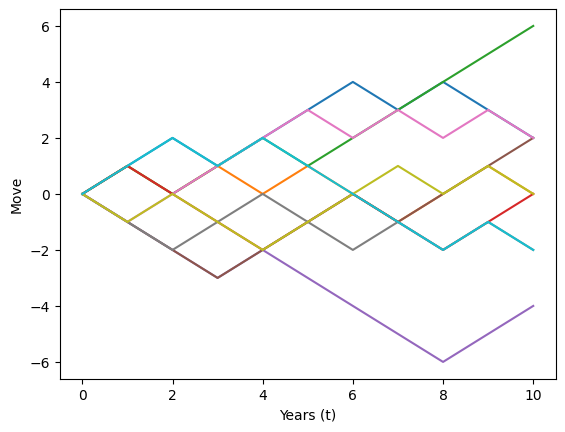

In [18]:
plt.plot(rw_paths)
plt.xlabel("Years (t)")
plt.ylabel("Move")
plt.show()

In [19]:
#create Quadratic variation and variance functions
quadratic_variation = lambda x: round(np.square(x[:-1] - x[1:]).sum(),3)
variance = lambda x: round(np.var(x,axis=0),3)

In [22]:
[quadratic_variation(path) for path in rw_paths.T[:4]]

[10.0, 10.0, 10.0, 10.0]

In [23]:
#10,000,000 simulations
[variance(path) for path in rw_paths[1:11]]

[1.0, 1.96, 2.44, 3.2, 3.36, 4.36, 5.8, 8.36, 7.04, 7.04]

Scaled symmetric random walk

In [24]:
#parameters
M = 10   #number of simulations
t = 10   #time
n = 10

In [25]:
random_walk = [-1, 1]
steps = (1/np.sqrt(n)) * np.random.choice(random_walk, size = (M,t*n)).T
origin = np.zeros((1,M))
srw_paths = np.concatenate([origin, steps]).cumsum(axis=0)

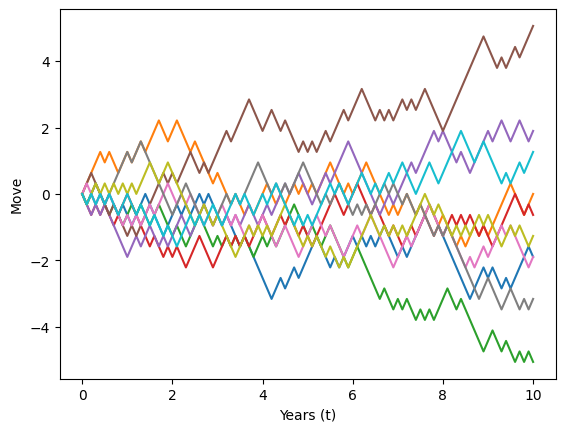

In [30]:
time = np.linspace(0,t,t*n+1)
tt = np.full(shape=(M, t*n+1), fill_value=time)
tt = tt.T
#print(np.szie(tt), np.size(srw_paths))
plt.plot(tt,srw_paths)
plt.xlabel("Years (t)")
plt.ylabel("Move")
plt.show()

In [31]:
# 100,000 simulations
[variance(path) for path in srw_paths[1:11]]

[0.084, 0.16, 0.176, 0.24, 0.164, 0.304, 0.304, 0.336, 0.64, 0.896]

In [32]:
[quadratic_variation(path) for path in srw_paths.T[:4]]

[10.0, 10.0, 10.0, 10.0]

Limit of binomial distribution

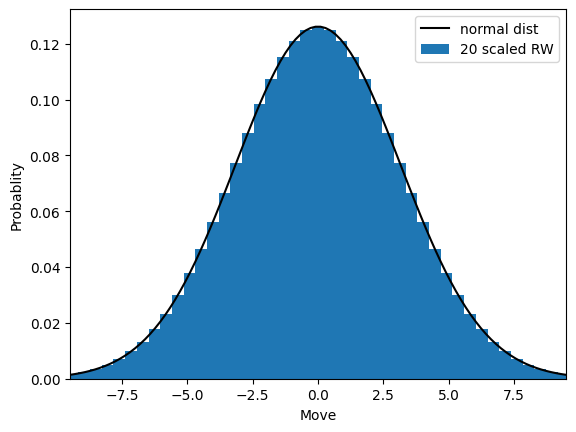

In [50]:
n = 20
t = 10

#combinations
def nCr(n,k):
    f = math.factorial
    return f(n) / (f(k) * f(n-k))

perms = [nCr(n*t,k)*(0.5)**(n*t) for k in range(int(n*t)+1)]

W_nt = lambda n,t: 1/np.sqrt(n) * np.arange(-n*t,n*t+1,2)

outcomes = W_nt(n,t)
plt.bar(outcomes,[perm/(outcomes[1]-outcomes[0]) for perm in perms],outcomes[1]-outcomes[0],
        label='{0} scaled RW'.format(n))


x = np.linspace(-3*np.sqrt(t), 3*np.sqrt(t), 100)
plt.plot(x, stats.norm.pdf(x, 0, np.sqrt(t)), 'k-',label='normal dist')

plt.xlim(-3*np.sqrt(t), 3*np.sqrt(t))
plt.ylabel("Probablity")
plt.xlabel("Move")
plt.legend()
plt.show()

In [51]:
#parameters
M = 10     #number of simulations
t = 10     #time
n = 100    #steps we want to see
dt = t/n   #time step

In [52]:
steps = np.random.normal(0, np.sqrt(dt), size=(M, n)).T
origin = np.zeros((1,M))
bm_paths = np.concatenate([origin, steps]).cumsum(axis=0)

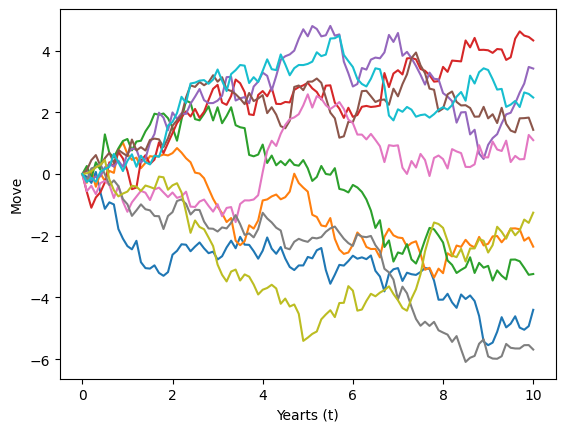

In [53]:
time = np.linspace(0,t,n+1)
tt = np.full(shape=(M,n+1), fill_value=time)
tt = tt.T

plt.plot(tt, bm_paths)
plt.xlabel("Yearts (t)")
plt.ylabel("Move")
plt.show()

In [54]:
# 1,000,000 time steps
[quadratic_variation(path) for path in bm_paths.T[:4]]

[9.318, 8.773, 12.754, 11.331]

In [58]:
#100,000 simulations
[variance(path) for path in bm_paths[1:11]]

[0.073, 0.156, 0.182, 0.106, 0.358, 0.233, 0.284, 0.673, 0.912, 1.069]

1.2.2 Simulating Geometric Brownian motion (GBM) 

In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
#drift coefficent
mu = 0.1
#number of steps
n = 100
#time in years
T = 1
#number of sims
M = 100
#initial stock price
S0 = 100
#volatility
sigma = 0.3

In [8]:
#calculate each time step
dt = T/n
#simualtion using numpy arrays
St = np.exp(
    (mu - sigma ** 2 / 2)*dt
    + sigma* np.random.normal(0, np.sqrt(dt), size=(M,n)).T
)
#include array of 1s
St = np.vstack([np.ones(M), St])
#multiply through by S0 and return the cumulative product of elements along a given simulation path (axis=0)
St = S0 * St.cumprod(axis=0)
St[1]

array([105.08007274, 104.13146589, 101.45458144,  99.49644028,
        98.27832937, 105.96743473,  92.87916912,  99.81135923,
       100.19866385,  99.0014654 , 101.93103836, 101.10333331,
        98.13775146, 100.84575165, 103.45069377, 103.65204675,
       100.31823365,  97.90554958,  96.35399592, 101.46970633,
        98.50866778, 101.78265837, 104.85971799,  98.39824615,
       107.54128275,  95.89840945, 104.55974566, 102.93189535,
        96.47476764, 100.52815017,  97.41470052,  95.15704635,
        99.1734623 ,  98.35349527, 102.17093418, 102.9216604 ,
        97.14806356, 104.21764528,  98.13078502,  99.64216742,
       104.08351404,  95.286264  ,  95.21294432, 102.62081792,
        98.96466601,  97.32410545,  99.14233163,  95.82368835,
       101.35283958, 101.84162869, 100.21907552, 104.28275485,
       102.77347832,  95.51931227,  98.45819495, 100.78340789,
        96.73304942,  97.75790961,  98.40150113,  97.38216797,
        97.00680077, 100.8781427 ,  95.38999973, 106.71

consider time intervals in years

In [10]:
#define time interval correctly
time = np.linspace(0,T,n+1)
#require numpy array that is the same shape as St
tt = np.full(shape=(M,n+1), fill_value=time).T

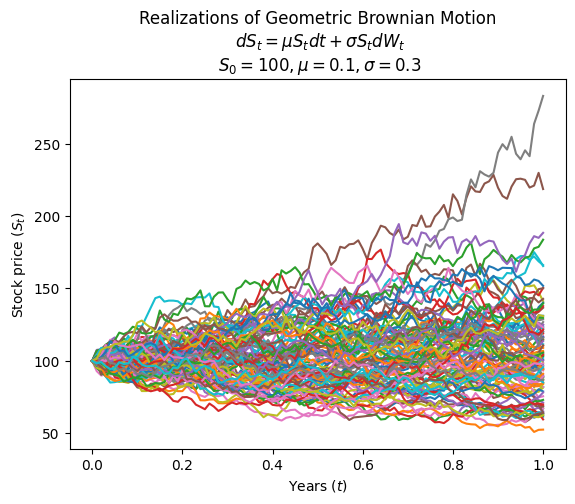

In [15]:
plt.plot(tt, St)
plt.xlabel("Years $(t)$")
plt.ylabel("Stock price $(S_t)$")
plt.title( 
    "Realizations of Geometric Brownian Motion\n $dS_t = \mu S_t dt + \sigma S_t dW_t$\n $S_0 = {0}, \mu = {1}, \sigma = {2}$".format(S0, mu, sigma)
)
plt.show()
